# Predict a cell’s full binary expression profile from morphology

This companion to [the morphology/expression exploration](joint_morphology_expression_tutorial.ipynb)
trains **CPU, non-neural predictors of all 201 measured gene calls**, using either frozen DINO
features or the original MorphoFeatures vectors. The earlier tutorial predicted only eight selected
genes with logistic regression; it did not fit a reusable full-panel predictor.

**What you should have:** the spatial binary-expression TSV, the cell-to-nucleus mapping, one embedding
vector per cell, and the previous exploration’s audited cohort, gene names and fold assignments.
Paths are configurable below. This example uses 11,377 matched cells after excluding five all-zero
profiles, exactly as before. It needs NumPy, pandas, scikit-learn, joblib, Matplotlib and this repository;
XGBoost is optional. It uses four CPU workers, no GPU, and can take several minutes or longer.

A profile is **201 simultaneous binary targets**, not a single class chosen from thousands of unique
profiles. A probability of 0.8 is a model score for a spatial on/off call, **not RNA abundance** or a
validated probability of biological truth. All probabilities are retained; binary calls initially use
0.5. No expression features, scLocator classes, cell IDs or coordinates enter the morphology models.
Coordinates are used only in a separately labelled control.

The current inputs are from one animal. Random splits measure interpolation within that animal;
spatial holdouts are a harder diagnostic. Neither establishes transfer to another specimen/species.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from decimal import Decimal
from time import perf_counter
import hashlib, importlib.util, importlib.metadata, json, resource, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits

REPO = Path('/g/kreshuk/frazer/projects/MorphoFeatures')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from morphofeatures.analysis.expression_prediction import (
    BinaryExpressionPredictor, embedding_preprocessor, profile_scores,
)

PREVIOUS_RUN = REPO / 'outputs/exploration/morphology_expression/20261002-163056'
EXPRESSION = Path('/g/kreshuk/frazer/data/platy_data/expression/sclocator/spatial_expr_df_binarized.tsv')
MAPPING = Path('/g/kreshuk/mansaray/platy_data/1.0.1/tables/sbem-6dpf-1-whole-segmented-cells/cells_to_nuclei.tsv')
DINO = REPO / 'outputs/experiments/DinoV2-b-reg-embedding-label-transfer-platy-par/workspace/00-transfer/reference/original_embeddings.npz'
MORPHOFEATURES = REPO / 'analysis/data/morphofeatures_all_cells.npy'

SEED = 42
WORKERS = 4                    # Explicit CPU budget; do not use all CPUs on a shared machine.
PCA_COMPONENTS = 100             # None = retain all original embedding dimensions.
THRESHOLD = 0.5                 # Fixed before evaluation. Do not tune against these test labels.
MINIMUM_CLASS_SIZE = 50         # Reporting filter only; ALL genes are still predicted.
MODEL_KINDS = ['logistic', 'random_forest', 'extra_trees', 'hist_gradient_boosting']
INCLUDE_XGBOOST = False         # Requires xgboost in this notebook's Python environment.
FIT_FINAL_MODELS = True         # Refit the best spatial-AP model for each embedding on all cells.
EXPORT_WIDE_TSV = True          # Gzipped OOF probability/call tables for the chosen models.
MODEL_OPTIONS = dict(trees=128, tree_depth=12, min_leaf=12, boosting_iterations=100,
                     boosting_leaves=7, logistic_c=10.0)
if INCLUDE_XGBOOST:
    if importlib.util.find_spec('xgboost') is None:
        raise ImportError('Install xgboost in this kernel environment, or set INCLUDE_XGBOOST=False.')
    MODEL_KINDS.append('xgboost')
print('XGBoost available:', importlib.util.find_spec('xgboost') is not None)

created = datetime.now(ZoneInfo('Europe/Berlin'))
OUT = REPO / 'outputs/exploration/full_expression_prediction' / created.strftime('%Y%m%d-%H%M%S')
OUT.mkdir(parents=True, exist_ok=False)
for folder in ['tables', 'predictions', 'models', 'figures']:
    (OUT / folder).mkdir()
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'svg.fonttype': 'none', 'figure.dpi': 110})

def table(df, name):
    df.to_csv(OUT / 'tables' / f'{name}.tsv', sep='\t', index=False)
    return df

def figure(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(OUT / 'figures' / f'{name}.{ext}', dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()

def fingerprint(path):
    path = Path(path)
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(chunk)
    return {'path': str(path), 'bytes': path.stat().st_size, 'sha256': digest.hexdigest()}

print('Output directory:', OUT)

XGBoost available: False
Output directory: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/full_expression_prediction/20261005-115249


## 1. Align by the right biological identity

Expression rows use **nucleus IDs**; these embedding files use **cell IDs**. We verify the explicit
mapping and order every matrix by the audited cell list. The first MorphoFeatures column is an ID,
not a feature. DINO inputs here are the original frozen features, not label-transfer/adapted features.
The two embedding sources describe different biological inputs (nuclear DINO texture versus the
original combined morphology representation), so their comparison is not an isolated encoder test.

The rare genes remain in the panel. If a training fold contains no positive examples, the model
uses a smoothed training prevalence and records the fallback. The constant-zero gene cannot be
learned; its output is retained for consistent column order, and its AP/AUC is marked undefined.

In [2]:
def exact_ids(values):
    numbers = [Decimal(str(value)) for value in values]
    if any(not n.is_finite() or n != n.to_integral_value() for n in numbers):
        raise ValueError('IDs must be exact integers.')
    ids = np.asarray([int(n) for n in numbers], dtype=np.int64)
    if len(np.unique(ids)) != len(ids):
        raise ValueError('Duplicate IDs would make the identity join ambiguous.')
    return ids

cohort = pd.read_csv(PREVIOUS_RUN / 'tables/spatial_and_pair_groups.tsv', sep='\t')
cell_ids = exact_ids(cohort.cell_id)
nucleus_ids = exact_ids(cohort.nucleus_id)
gene_qc = pd.read_csv(PREVIOUS_RUN / 'tables/gene_dictionary_and_qc.tsv', sep='\t')
expr = pd.read_csv(EXPRESSION, sep='\t', index_col=0)
expr.index = exact_ids(expr.index)
if not expr.columns.is_unique or not np.isin(expr.to_numpy(), [0, 1]).all():
    raise ValueError('Expected unique gene columns and finite binary expression.')
gene_ids = expr.columns.to_numpy(dtype=str)
Y = expr.loc[nucleus_ids].to_numpy(dtype=np.uint8)
assert (Y.sum(axis=1) > 0).all(), 'This example reuses the previous nonempty-profile cohort.'
gene_names = gene_qc.set_index('XLOC').loc[gene_ids, 'vis_name'].fillna('').to_numpy(dtype=str)

mapping = pd.read_csv(MAPPING, sep='\t').set_index('label_id')
np.testing.assert_array_equal(mapping.loc[cell_ids, 'nucleus_id'].to_numpy(dtype=np.int64), nucleus_ids)
with np.load(DINO, allow_pickle=False) as z:
    dino_ids = exact_ids(z['label_ids'])
    dino_features = pd.DataFrame(z['features'], index=dino_ids).loc[cell_ids].to_numpy(dtype=np.float32)
morpho = np.load(MORPHOFEATURES, allow_pickle=False)
morpho_ids = exact_ids(morpho[:, 0])
morpho_features = pd.DataFrame(morpho[:, 1:], index=morpho_ids).loc[cell_ids].to_numpy(dtype=np.float32)
X = {'DINO': dino_features, 'MorphoFeatures': morpho_features}
assert all(len(a) == len(Y) and np.isfinite(a).all() for a in X.values())
XYZ = cohort[['x', 'y', 'z']].to_numpy(dtype=float)
assert np.isfinite(XYZ).all()
fold_path = PREVIOUS_RUN / 'vectors/gene_predictions_out_of_fold.npz'
with np.load(fold_path, allow_pickle=False) as z:
    np.testing.assert_array_equal(z['label_ids'], cell_ids)
    np.testing.assert_array_equal(z['nucleus_ids'], nucleus_ids)
    folds = {name: z[name + '__fold'].copy() for name in ['random_pair_grouped', 'spatial']}
    old_genes = z['gene_ids'].copy()
    np.testing.assert_array_equal(z['observed_binary'], expr.loc[nucleus_ids, old_genes].to_numpy())
for scheme, fold_ids in folds.items():
    assert (fold_ids >= 0).all() and len(np.unique(fold_ids)) >= 2
    cohort[scheme + '_fold'] = fold_ids
    for fold in np.unique(fold_ids):
        tr, te = fold_ids != fold, fold_ids == fold
        group = 'pair_group' if scheme == 'random_pair_grouped' else 'spatial_region'
        assert not set(cohort.loc[tr, group]) & set(cohort.loc[te, group])

table(cohort, 'cohort_and_folds')
counts = Y.sum(axis=0)
genes = table(pd.DataFrame({'gene_id': gene_ids, 'gene_name': gene_names,
    'positive_cells': counts, 'negative_cells': len(Y)-counts, 'prevalence': Y.mean(axis=0),
    'constant': (counts == 0) | (counts == len(Y)),
    'supported': np.minimum(counts, len(Y)-counts) >= MINIMUM_CLASS_SIZE}), 'gene_panel')
print(f'{len(Y):,} cells × {Y.shape[1]} gene targets; {int(genes.constant.sum())} constant; '
      f'{int(genes.supported.sum())} have at least {MINIMUM_CLASS_SIZE} cells of each class.')
display(genes.nsmallest(12, 'positive_cells'))

11,377 cells × 201 gene targets; 1 constant; 191 have at least 50 cells of each class.


,gene_id,gene_name,positive_cells,negative_cells,prevalence,constant,supported
85,XLOC-019991,Tan,0,11377,0.000000,True,False
168,XLOC-052630,Maob,2,11375,0.000176,False,False
51,XLOC-006910,FunkyOpsin,4,11373,0.000352,False,False
90,XLOC-021495,Vsx2,14,11363,0.001231,False,False
105,XLOC-026284,uncs,22,11355,0.001934,False,False
17,XLOC-001605,Hdc,23,11354,0.002022,False,False
162,XLOC-051606,Nkx3.2,37,11340,0.003252,False,False
88,XLOC-021309,Foxg1,40,11337,0.003516,False,False
146,XLOC-043332,gpcr2,40,11337,0.003516,False,False
69,XLOC-012580,globin-like,47,11330,0.004131,False,False


## 2. What is being compared?

| Predictor | What it learns | Why include it? |
|---|---|---|
| Training prevalence | One training-set probability per gene | Minimum useful baseline; no cell features |
| Position KNN | Profiles of 50 spatially nearby training nuclei | Tests how much location alone explains |
| Logistic regression | One linear probability model per gene | Extends the previous eight-gene baseline to the whole panel |
| Random forest | An ensemble of trees with splits shared across all genes | Nonlinear, genuine multioutput model; frequent targets may dominate shared splits |
| Extra Trees | Shared multioutput trees with more randomized split thresholds | A different variance/bias trade-off from random forests |
| Histogram gradient boosting | A separate sequence of shallow boosted trees per gene | Nonlinear interactions; scalable alternative to classic gradient boosting |
| XGBoost (optional) | Independent histogram-boosted binary model per gene | Available if installed and enabled; not a required dependency |

Every row except the first two is run on **DINO and MorphoFeatures separately**. All four model
families receive the same training-centered → row-L2-normalized → PCA features. Set
`PCA_COMPONENTS=None` to test the full-dimensional features in a separate recorded run; PCA can
remove subtle gene-relevant signals, and trees may prefer a different representation. No UMAP
coordinates enter these predictors. The models are bounded first-pass settings, not optimized winners.

**Validation:** reuse exactly the earlier three random pair-grouped folds and four spatial folds.
Known bilateral partners stay together in the random splits. Spatial folds hold out entire regions,
but some bilateral pairs cross spatial folds; the diagnostics count these explicitly. There is no
spatial exclusion buffer and only one animal. Gene correlations and spatial autocorrelation mean
cell-wise confidence intervals would exaggerate precision; fold scores are exported instead.

All centering/PCA/model fitting occurs inside the training fold. Gradient boosting uses no internal
random early-stopping split. We do not rebalance labels or tune thresholds on test cells. Constant
training targets get `(positive_count + 1) / (training_count + 2)` for every classifier.

In [3]:
versions = {package: importlib.metadata.version(package) for package in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib', 'matplotlib']}
if INCLUDE_XGBOOST:
    versions['xgboost'] = importlib.metadata.version('xgboost')
source_paths = [EXPRESSION, MAPPING, DINO, MORPHOFEATURES, fold_path,
    PREVIOUS_RUN / 'tables/spatial_and_pair_groups.tsv',
    PREVIOUS_RUN / 'tables/gene_dictionary_and_qc.tsv',
    REPO / 'morphofeatures/analysis/expression_prediction.py']
provenance = {'schema': 'full_expression_prediction.v1', 'created': created.isoformat(),
    'status': 'running', 'python': sys.version, 'versions': versions,
    'sources': [fingerprint(p) for p in source_paths], 'previous_run': str(PREVIOUS_RUN),
    'settings': {'seed': SEED, 'workers': WORKERS, 'pca_components': PCA_COMPONENTS,
        'threshold': THRESHOLD, 'minimum_class_size_reporting_only': MINIMUM_CLASS_SIZE,
        'models': MODEL_KINDS, 'model_options': MODEL_OPTIONS,
        'preprocessing': 'training mean centering -> row L2 -> optional unwhitened PCA',
        'final_model_selection': 'highest spatial macro AP among genes with >=50 positives/negatives'},
    'id_namespaces': {'label_ids': 'cell', 'nucleus_ids': 'nucleus'},
    'cells': len(Y), 'genes': len(gene_ids),
    'limits': ['one EM specimen', 'thresholded spatial calls, not RNA abundance',
        'spatial folds have no buffer and can split bilateral pairs',
        'final model selection reuses CV results; no independent winner-validation set',
        'five all-zero profiles excluded to match previous exploration']}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))

predictions, diagnostics, timings, pca_rows = {}, [], [], []
started = perf_counter()
for scheme, fold_ids in folds.items():
    print(f'\n{scheme}: {len(np.unique(fold_ids))} folds', flush=True)
    names = ['Prior', 'Position'] + [f'{embedding} / {kind}' for embedding in X for kind in MODEL_KINDS]
    predictions[scheme] = {name: np.full(Y.shape, np.nan, dtype=np.float32) for name in names}
    for fold in np.unique(fold_ids):
        tr, te = np.flatnonzero(fold_ids != fold), np.flatnonzero(fold_ids == fold)
        train_y = Y[tr]
        positive = train_y.sum(axis=0)
        constant = (positive == 0) | (positive == len(tr))
        cross_pairs = len(set(cohort.iloc[tr].pair_group) & set(cohort.iloc[te].pair_group))
        for j, gene in enumerate(gene_ids):
            diagnostics.append({'scheme': scheme, 'fold': int(fold), 'gene_id': gene,
                'train_cells': len(tr), 'test_cells': len(te), 'train_positive': int(positive[j]),
                'test_positive': int(Y[te, j].sum()), 'prior_fallback_all_classifiers': bool(constant[j]),
                'cross_fold_bilateral_groups': cross_pairs})
        predictions[scheme]['Prior'][te] = (positive + 1) / (len(tr) + 2)
        with threadpool_limits(limits=1):
            control = KNeighborsRegressor(n_neighbors=min(50, len(tr)), weights='distance', n_jobs=WORKERS)
            predictions[scheme]['Position'][te] = control.fit(XYZ[tr], train_y).predict(XYZ[te])
        for embedding, values in X.items():
            t0 = perf_counter()
            prep = embedding_preprocessor(PCA_COMPONENTS, seed=SEED)
            with threadpool_limits(limits=WORKERS):
                train_X = prep.fit_transform(values[tr]).astype(np.float32)
                test_X = prep.transform(values[te]).astype(np.float32)
            pca_rows.append({'scheme': scheme, 'fold': int(fold), 'embedding': embedding,
                'input_dimensions': values.shape[1], 'model_dimensions': train_X.shape[1],
                'training_explained_variance': float(prep.steps[-1][1].explained_variance_ratio_.sum())
                    if PCA_COMPONENTS is not None else 1.0, 'seconds': perf_counter()-t0})
            for kind in MODEL_KINDS:
                name = f'{embedding} / {kind}'
                print(f'  fold {fold+1}: {name}', flush=True)
                t0 = perf_counter()
                model = BinaryExpressionPredictor(kind, workers=WORKERS, seed=SEED,
                    threshold=THRESHOLD, **MODEL_OPTIONS).fit(train_X, train_y)
                predictions[scheme][name][te] = model.predict_proba(test_X)
                elapsed = perf_counter()-t0
                timings.append({'scheme': scheme, 'fold': int(fold), 'embedding': embedding,
                    'model': kind, 'fit_and_predict_seconds': elapsed,
                    'peak_process_RSS_MiB': resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024})
                print(f'    {elapsed:.1f} seconds', flush=True)
                del model
        # Checkpoint after every completed fold. Unvisited rows remain NaN until the run completes.
        for name, values in predictions[scheme].items():
            key = name.lower().replace(' / ', '__').replace(' ', '_')
            np.savez_compressed(OUT / 'predictions' / f'{scheme}__{key}.npz',
                label_ids=cell_ids, nucleus_ids=nucleus_ids, gene_ids=gene_ids,
                observed_binary=Y, probability=values, fold=fold_ids,
                complete=np.asarray(bool(np.isfinite(values).all())))
        table(pd.DataFrame(timings), 'training_times')
        table(pd.DataFrame(diagnostics), 'fold_gene_diagnostics')
        table(pd.DataFrame(pca_rows), 'fold_preprocessing')
    assert all(np.isfinite(p).all() for p in predictions[scheme].values())
print(f'Cross-validation finished in {(perf_counter()-started)/60:.1f} minutes.')


random_pair_grouped: 3 folds
  fold 1: DINO / logistic
    3.8 seconds
  fold 1: DINO / random_forest
    17.6 seconds
  fold 1: DINO / extra_trees
    4.4 seconds
  fold 1: DINO / hist_gradient_boosting
    90.8 seconds
  fold 1: MorphoFeatures / logistic
    1.8 seconds
  fold 1: MorphoFeatures / random_forest
    18.5 seconds
  fold 1: MorphoFeatures / extra_trees
    5.0 seconds
  fold 1: MorphoFeatures / hist_gradient_boosting
    88.2 seconds
  fold 2: DINO / logistic
    3.9 seconds
  fold 2: DINO / random_forest
    18.0 seconds
  fold 2: DINO / extra_trees
    4.9 seconds
  fold 2: DINO / hist_gradient_boosting
    90.9 seconds
  fold 2: MorphoFeatures / logistic
    1.9 seconds
  fold 2: MorphoFeatures / random_forest
    18.5 seconds
  fold 2: MorphoFeatures / extra_trees
    5.1 seconds
  fold 2: MorphoFeatures / hist_gradient_boosting
    91.5 seconds
  fold 3: DINO / logistic
    3.9 seconds
  fold 3: DINO / random_forest
    17.7 seconds
  fold 3: DINO / extra_trees
   

## 3. Read the scores without being misled by mostly negative genes

**Average precision (AP)** asks whether positive cells rank above negative cells; larger is better.
Its chance reference is approximately gene prevalence, so inspect AP above prevalence as well as AP.
Macro AP gives each variable gene equal weight; “supported” macro AP excludes genes with fewer than
50 positive or negative cells **from that summary only**. Micro AP pools all gene/cell pairs and is
influenced by common genes. Rare-gene estimates remain in the per-gene table, with their counts.

Brier score and log loss assess probabilities (lower is better). Their improvement over the held-out
training-prior predictions is useful. At a fixed threshold of 0.5, F1 and per-cell Jaccard assess the
predicted set of active genes. Hamming loss can look good by predicting everything absent; exact
profile accuracy can be almost zero even for useful predictions because all 201 calls must match.
We report both, but do not use either to choose the best model.

These probabilities have not been independently calibrated. For reliable binary calls, choose
per-gene thresholds/calibration using **inner training folds**, then evaluate once on untouched
outer folds or another specimen. Changing thresholds after seeing these test outcomes is exploratory.

In [4]:
summary_rows, gene_tables, fold_rows = [], [], []
for scheme, methods in predictions.items():
    for name, p in methods.items():
        score, per_gene = profile_scores(Y, p, gene_ids, threshold=THRESHOLD,
                                         minimum_class_size=MINIMUM_CLASS_SIZE)
        summary_rows.append({'scheme': scheme, 'method': name, **score})
        per_gene.insert(0, 'method', name)
        per_gene.insert(0, 'scheme', scheme)
        per_gene['gene_name'] = gene_names
        gene_tables.append(per_gene)
        for fold in np.unique(folds[scheme]):
            te = folds[scheme] == fold
            fold_score, _ = profile_scores(Y[te], p[te], gene_ids, threshold=THRESHOLD,
                                           minimum_class_size=MINIMUM_CLASS_SIZE)
            fold_rows.append({'scheme': scheme, 'fold': int(fold), 'method': name, **fold_score})
scores = pd.DataFrame(summary_rows)
prior_loss = scores[scores.method == 'Prior'].set_index('scheme').log_loss_nats
scores['log_loss_gain_bits_vs_prior'] = [
    (prior_loss[scheme]-loss)/np.log(2) for scheme, loss in zip(scores.scheme, scores.log_loss_nats)]
gene_scores = pd.concat(gene_tables, ignore_index=True)
prior_genes = gene_scores[gene_scores.method == 'Prior'][['scheme', 'gene_id', 'log_loss_nats']].rename(
    columns={'log_loss_nats': 'prior_log_loss_nats'})
gene_scores = gene_scores.merge(prior_genes, on=['scheme', 'gene_id'], validate='many_to_one')
gene_scores['log_loss_gain_bits_vs_prior'] = (
    gene_scores.prior_log_loss_nats-gene_scores.log_loss_nats)/np.log(2)
table(scores, 'profile_scores')
table(gene_scores, 'per_gene_scores')
table(pd.DataFrame(fold_rows), 'per_fold_profile_scores')
columns = ['scheme', 'method', 'macro_AP', 'macro_AP_supported', 'micro_AP', 'brier',
           'micro_F1', 'mean_cell_Jaccard', 'exact_profile_accuracy']
display(scores[columns].round(4))

# Directly comparable check on the original eight targets, now predicted by each full-panel model.
eight = gene_scores[gene_scores.gene_id.isin(old_genes)].groupby(['scheme', 'method'], as_index=False)[
    ['average_precision', 'roc_auc', 'log_loss_gain_bits_vs_prior']].mean()
table(eight, 'previous_eight_gene_comparison')

,scheme,method,macro_AP,macro_AP_supported,micro_AP,brier,micro_F1,mean_cell_Jaccard,exact_profile_accuracy
0,random_pair_grouped,Prior,0.0969,0.1013,0.3287,0.0760,0.1405,0.0831,0.0000
1,random_pair_grouped,Position,0.6164,0.6374,0.7742,0.0425,0.6331,0.4209,0.0016
2,random_pair_grouped,DINO / logistic,0.3190,0.3322,0.5632,0.0603,0.4485,0.2719,0.0004
3,random_pair_grouped,DINO / random_forest,0.3165,0.3287,0.5122,0.0654,0.3066,0.1738,0.0003
4,random_pair_grouped,DINO / extra_trees,0.3159,0.3279,0.4709,0.0683,0.2446,0.1398,0.0003
5,random_pair_grouped,DINO / hist_gradient_boosting,0.3237,0.3361,0.5559,0.0610,0.4288,0.2595,0.0006
6,random_pair_grouped,MorphoFeatures / logistic,0.3387,0.3508,0.5770,0.0593,0.4811,0.2970,0.0002
7,random_pair_grouped,MorphoFeatures / random_forest,0.3226,0.3345,0.5282,0.0641,0.3428,0.1999,0.0004
8,random_pair_grouped,MorphoFeatures / extra_trees,0.3236,0.3352,0.4890,0.0672,0.2797,0.1592,0.0003
9,random_pair_grouped,MorphoFeatures / hist_gradient_boosting,0.3275,0.3401,0.5658,0.0602,0.4485,0.2756,0.0002


,scheme,method,average_precision,roc_auc,log_loss_gain_bits_vs_prior
0,random_pair_grouped,DINO / extra_trees,0.471598,0.741124,0.062146
1,random_pair_grouped,DINO / hist_gradient_boosting,0.481410,0.746669,0.115189
2,random_pair_grouped,DINO / logistic,0.488868,0.759218,0.125288
3,random_pair_grouped,DINO / random_forest,0.479077,0.748280,0.084262
4,random_pair_grouped,MorphoFeatures / extra_trees,0.485572,0.756062,0.069782
5,random_pair_grouped,MorphoFeatures / hist_gradient_boosting,0.487253,0.755554,0.123023
6,random_pair_grouped,MorphoFeatures / logistic,0.493225,0.761943,0.128692
7,random_pair_grouped,MorphoFeatures / random_forest,0.486169,0.755880,0.095300
8,random_pair_grouped,Position,0.680461,0.880080,0.266656
9,random_pair_grouped,Prior,0.259411,0.492388,0.000000


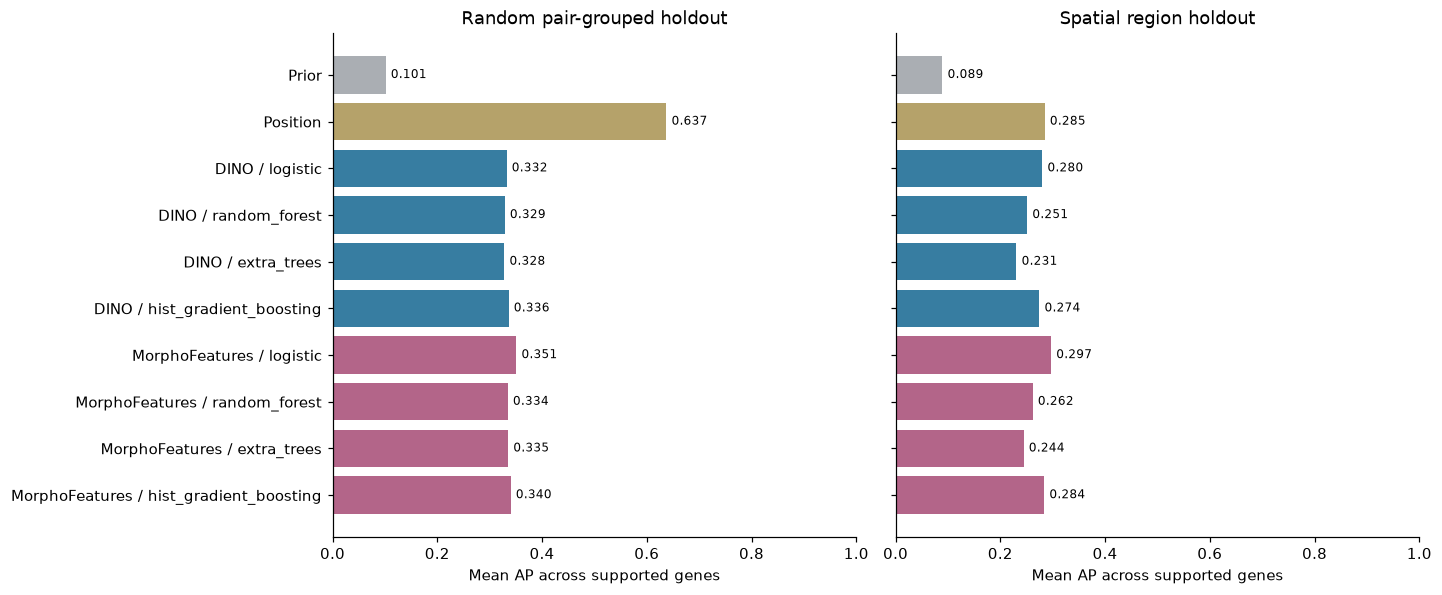

Exploratory selection for final refitting: {'DINO': 'DINO / logistic', 'MorphoFeatures': 'MorphoFeatures / logistic'}


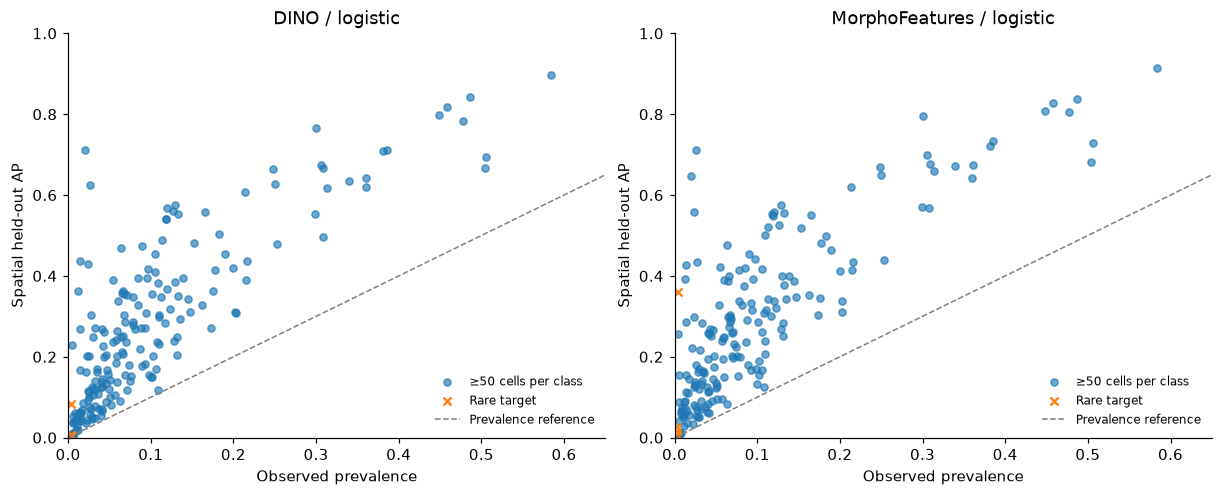

In [6]:
method_order = list(predictions['spatial'])
colors = ['#aaaeb3' if m == 'Prior' else '#b5a26a' if m == 'Position' else
          '#377da1' if m.startswith('DINO') else '#b36589' for m in method_order]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), sharex=True, sharey=True, layout='constrained')
for ax, scheme in zip(axes, folds):
    frame = scores[scores.scheme == scheme].set_index('method').loc[method_order]
    ax.barh(np.arange(len(frame)), frame.macro_AP_supported, color=colors)
    ax.set(yticks=np.arange(len(frame)), yticklabels=method_order, xlabel='Mean AP across supported genes',
           title='Random pair-grouped holdout' if scheme.startswith('random') else 'Spatial region holdout',
           xlim=(0, 1))
    for i, value in enumerate(frame.macro_AP_supported):
        ax.text(value+.01, i, f'{value:.3f}', va='center', fontsize=8)
axes[0].invert_yaxis()
figure(fig, 'full_panel_model_comparison')

winners = {}
for embedding in X:
    candidates = scores[(scores.scheme == 'spatial') & scores.method.str.startswith(embedding+' / ')]
    winners[embedding] = candidates.sort_values('macro_AP_supported', ascending=False).iloc[0]['method']
print('Exploratory selection for final refitting:', winners)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
for ax, (embedding, name) in zip(axes, winners.items()):
    frame = gene_scores[(gene_scores.scheme == 'spatial') & (gene_scores.method == name)]
    common = frame[frame.supported]
    rare = frame[~frame.supported & frame.variable]
    ax.scatter(common.prevalence, common.average_precision, s=22, alpha=.65, label='≥50 cells per class')
    ax.scatter(rare.prevalence, rare.average_precision, s=28, marker='x', label='Rare target')
    ax.plot([0, 1], [0, 1], '--', color='.5', linewidth=1, label='Prevalence reference')
    ax.set(xlabel='Observed prevalence', ylabel='Spatial held-out AP', title=name, xlim=(0, .65), ylim=(0, 1))
    ax.legend(loc='lower right', fontsize=8, frameon=False)
figure(fig, 'per_gene_spatial_prediction')

## 4. Inspect entire predicted profiles

The following heatmaps show **held-out spatial predictions**, not fitted values from the final model.
Cells are a deterministic sample spread along nucleus z-coordinate; genes are ordered by prevalence.
The same cells/genes appear in all panels. Inspect common and rare genes separately before deciding
whether the predicted profiles are biologically useful. The compressed NPZ files retain every cell,
all 201 probabilities, observed calls, cell/nucleus IDs and outer-fold assignments.

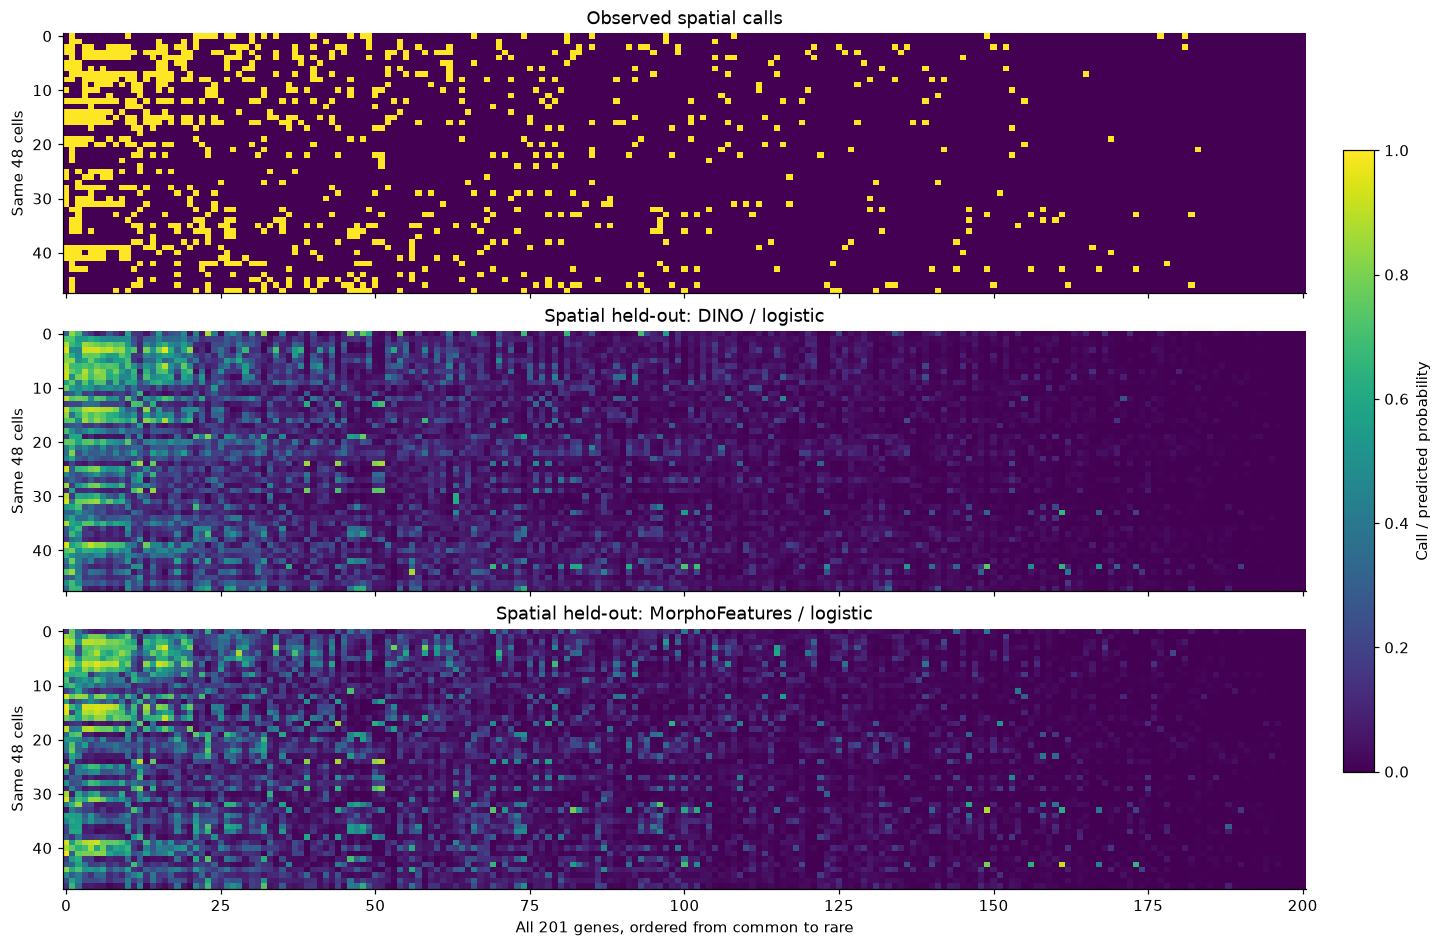

,heatmap_column,gene_id,gene_name
0,0,XLOC-011991,scn8aa
1,1,XLOC-002098,rab3
2,2,XLOC-011941,phc2
3,3,XLOC-000875,syt
4,4,XLOC-001549,Elav
...,...,...,...
196,196,XLOC-026284,uncs
197,197,XLOC-021495,Vsx2
198,198,XLOC-006910,FunkyOpsin
199,199,XLOC-052630,Maob


In [6]:
row_order = np.argsort(XYZ[:, 2])
rows = row_order[np.linspace(0, len(row_order)-1, 48).astype(int)]
cols = np.argsort(-Y.mean(axis=0))
fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True, sharey=True, layout='constrained')
images = [('Observed spatial calls', Y)] + [
    (f'Spatial held-out: {name}', predictions['spatial'][name]) for name in winners.values()]
for ax, (name, values) in zip(axes, images):
    im = ax.imshow(values[np.ix_(rows, cols)], aspect='auto', interpolation='nearest',
                   cmap='viridis', vmin=0, vmax=1)
    ax.set(title=name, ylabel='Same 48 cells')
axes[-1].set_xlabel('All 201 genes, ordered from common to rare')
fig.colorbar(im, ax=axes.tolist(), label='Call / predicted probability', fraction=.025, pad=.02)
figure(fig, 'held_out_full_profiles')
table(pd.DataFrame({'heatmap_row': np.arange(len(rows)), 'cell_id': cell_ids[rows],
                    'nucleus_id': nucleus_ids[rows]}), 'heatmap_cell_order')
table(pd.DataFrame({'heatmap_column': np.arange(len(cols)), 'gene_id': gene_ids[cols],
                    'gene_name': gene_names[cols]}), 'heatmap_gene_order')

## 5. Fit and save a reusable full-profile predictor

For each embedding source, we now refit the model with the highest **spatial supported-gene macro AP**
on all 11,377 cells, including freshly fitted preprocessing. This gives one reusable predictor per
embedding type. The final refit is **not** a new independent test: selection reused cross-validation
results, so do not treat the selected score as unbiased evidence of superiority. Validate the selected
recipe on another specimen, or use nested validation, before making that claim.

Each `.joblib` bundle contains the fitted pipeline, ordered gene IDs/names, threshold, input dimension,
training cell/nucleus IDs, input fingerprints and model choices. Load only trusted model files.
**Use the same embedding recipe and feature order** on new cells. Cell IDs need not overlap, but a
matching vector dimension alone does not establish compatibility across models or specimens.
The accompanying JSON describes the bundle without loading it. No final in-sample scores are reported.
The wide TSVs are **spatial out-of-fold** predictions on these cells, not predictions from the refit.

In [7]:
final_rows = []
if FIT_FINAL_MODELS:
    for embedding, name in winners.items():
        kind = name.split(' / ')[1]
        print(f'Refitting complete profile: {embedding}, {kind}', flush=True)
        t0 = perf_counter()
        prep = embedding_preprocessor(PCA_COMPONENTS, seed=SEED)
        with threadpool_limits(limits=WORKERS):
            transformed = prep.fit_transform(X[embedding]).astype(np.float32)
        estimator = BinaryExpressionPredictor(kind, workers=WORKERS, seed=SEED,
            threshold=THRESHOLD, **MODEL_OPTIONS).fit(transformed, Y)
        pipeline = make_pipeline(prep, estimator)
        slug = embedding.lower()
        metadata = {'schema': 'binary_expression_predictor.v1', 'embedding': embedding,
            'model': kind, 'model_options': MODEL_OPTIONS, 'input_features': X[embedding].shape[1],
            'gene_ids': gene_ids.tolist(), 'gene_names': gene_names.tolist(), 'threshold': THRESHOLD,
            'preprocessing': provenance['settings']['preprocessing'], 'pca_components': PCA_COMPONENTS,
            'trained_cells': len(Y), 'training_id_namespace': 'cell', 'versions': versions,
            'selection': provenance['settings']['final_model_selection'],
            'evaluation': 'see spatial OOF scores; final model itself is fitted on every cohort cell',
            'sources': provenance['sources'], 'constant_targets': gene_ids[estimator.constant_targets_].tolist()}
        bundle = {'pipeline': pipeline, 'metadata': metadata,
                  'training_cell_ids': cell_ids, 'training_nucleus_ids': nucleus_ids}
        path = OUT / 'models' / f'{slug}_full_profile.joblib'
        joblib.dump(bundle, path, compress=3)
        (path.with_suffix('.json')).write_text(json.dumps(metadata, indent=2))
        reloaded = joblib.load(path)
        with threadpool_limits(limits=WORKERS):
            expected = pipeline.predict_proba(X[embedding][:32])
            actual = reloaded['pipeline'].predict_proba(X[embedding][:32])
        # Float32 PCA array layout can change the last few rounding bits after serialization.
        np.testing.assert_allclose(actual, expected, rtol=0, atol=1e-6)
        final_rows.append({'embedding': embedding, 'model': kind, 'model_file': str(path),
            'seconds': perf_counter()-t0, 'bytes': path.stat().st_size,
            'reload_max_absolute_difference': float(np.max(np.abs(actual-expected)))})
        if EXPORT_WIDE_TSV:
            p = predictions['spatial'][name]
            for suffix, values in [('probabilities', p), ('binary_calls', (p >= THRESHOLD).astype(np.uint8))]:
                frame = pd.DataFrame(values, columns=gene_ids)
                frame.insert(0, 'nucleus_id', nucleus_ids)
                frame.insert(0, 'cell_id', cell_ids)
                frame.to_csv(OUT / 'predictions' / f'{slug}_spatial_oof_{suffix}.tsv.gz',
                             sep='\t', index=False, float_format='%.6g', compression='gzip')
        print(f'  Saved and reload-checked {path.name}', flush=True)
        del bundle, reloaded, pipeline, estimator
    table(pd.DataFrame(final_rows), 'final_models')

Refitting complete profile: DINO, logistic


  Saved and reload-checked dino_full_profile.joblib


Refitting complete profile: MorphoFeatures, logistic


  Saved and reload-checked morphofeatures_full_profile.joblib


### Apply a saved predictor later

```python
import joblib
bundle = joblib.load('.../models/dino_full_profile.joblib')  # trusted file, matching environment
# new_embeddings: N × 768, same frozen DINO recipe/feature order as the training input.
p = bundle['pipeline'].predict_proba(new_embeddings)       # N × 201 probabilities
calls = p >= bundle['metadata']['threshold']               # N × 201 binary calls
gene_ids = bundle['metadata']['gene_ids']                  # exact output column order
```

Keep your new cell/nucleus ID mapping next to these rows. Do not concatenate measured expression onto
the inputs: that would leak the answer. Do not pass PCA scores into this saved pipeline: it expects
original embedding vectors and applies its saved preprocessing itself. Training-prior fallbacks and
very rare genes deserve particular caution on new data.

The `predictions/*npz` files can also be loaded with `np.load(..., allow_pickle=False)` and joined
back to MoBIE/volume tables using `label_ids` (cell) or `nucleus_ids` (nucleus). Predicted gene columns
should be clearly prefixed as predictions and shown separately from measured spatial expression.

In [8]:
provenance.update(status='complete', elapsed_seconds=perf_counter()-started,
    peak_process_RSS_MiB=max(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024,
        pd.read_csv(OUT / 'tables/training_times.tsv', sep='\t').peak_process_RSS_MiB.max()),
    selected_final_models=winners, final_models=final_rows)
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))

lines = ['# Full binary-expression prediction', '',
    f'Executed {created.isoformat()}: {len(Y):,} matched cells, {len(gene_ids)} targets.', '',
    'The previous tutorial predicted eight selected genes. This benchmark predicts all 201.',
    'Only morphology embeddings enter the morphology models. Position and training-prior controls are separate.',
    f'All model families use the same training-only preprocessing with PCA={PCA_COMPONENTS}.', '',
    '| Split | Method | Macro AP (200 variable genes) | Supported macro AP | Micro AP | Micro F1 at 0.5 | Brier |',
    '|---|---|---:|---:|---:|---:|---:|']
for row in scores.itertuples():
    lines.append(f'| {row.scheme} | {row.method} | {row.macro_AP:.3f} | '
                 f'{row.macro_AP_supported:.3f} | {row.micro_AP:.3f} | {row.micro_F1:.3f} | {row.brier:.4f} |')
lines += ['', '## Interpretation and limits', '',
    'Higher AP indicates better ranking, not calibrated probabilities or reconstructed RNA abundances.',
    'Supported macro AP requires at least 50 positives and negatives per gene; the full panel is always exported.',
    'The fixed 0.5 threshold can miss rare positives; threshold tuning requires nested training-only validation.',
    'Random folds preserve bilateral pairs. Spatial folds hold out regions, but have no buffer and can split pairs.',
    'All cells are from one animal. These scores do not establish another-animal/species performance.',
    'Models have modest fixed CPU settings, not exhaustive hyperparameter tuning. XGBoost ran only if explicitly enabled.',
    'Final model selection reuses spatial CV scores; winner selection requires independent confirmation.',
    'The final saved models are refitted on all cells and were checked by reloading; held-out scores refer to fold models.', '',
    '## Files', '',
    '- `tables/profile_scores.tsv`: whole-panel metrics; `per_gene_scores.tsv`: all genes including rare/constant targets.',
    '- `tables/per_fold_profile_scores.tsv`, `cohort_and_folds.tsv`, `fold_gene_diagnostics.tsv`: auditable validation.',
    '- `predictions/*.npz`: all held-out probabilities, observed calls, IDs, gene order and fold assignments.',
    '- `predictions/*tsv.gz`: selected-model spatial OOF probabilities and binary calls.',
    '- `models/*joblib` and matching JSON: reusable full-panel predictors plus provenance.',
    '- `figures/`: PNG and SVG comparisons and full-profile heatmaps.',
    '- `provenance.json`: source hashes, settings, versions, timing and final model selection.', '',
    f'Elapsed: {provenance["elapsed_seconds"]/60:.1f} minutes; peak process RSS '
    f'{provenance["peak_process_RSS_MiB"]:.0f} MiB.', '']
interpretation = ['## Results from this run', '']
for embedding, name in winners.items():
    row = scores[(scores.scheme == 'spatial') & (scores.method == name)].iloc[0]
    interpretation.append(f'- {embedding}: {name.split(" / ")[1]} had the highest supported-gene spatial '
        f'macro AP ({row.macro_AP_supported:.3f}); micro F1 at 0.5 was {row.micro_F1:.3f}.')
position = scores[(scores.scheme == 'spatial') & (scores.method == 'Position')].iloc[0]
interpretation += [
    f'- Position alone achieved supported-gene spatial macro AP {position.macro_AP_supported:.3f}. '
    'Location remains a strong alternative explanation for part of the expression signal.',
    '- Under these fixed settings, extra model complexity did not outperform logistic regression on spatial holdouts. '
    'This does not rule out gains from other preprocessing, nested tuning or other model families.',
    '- Exact 201-gene profile matches are very rare. These models recover partial predictive signal; '
    'they do not reliably reconstruct every measured gene call.', '']
lines = lines[:7] + [''] + interpretation + lines[7:]
(OUT / 'findings.md').write_text('\n'.join(lines))
from IPython.display import Markdown
display(Markdown('\n'.join(interpretation)))
print('Saved report:', OUT / 'findings.md')
print('Saved models:', OUT / 'models')
display(pd.DataFrame(final_rows))

## Results from this run

- DINO: logistic had the highest supported-gene spatial macro AP (0.267); micro F1 at 0.5 was 0.402.
- MorphoFeatures: logistic had the highest supported-gene spatial macro AP (0.276); micro F1 at 0.5 was 0.420.
- Position alone achieved supported-gene spatial macro AP 0.285. Location remains a strong alternative explanation for part of the expression signal.
- Under these fixed settings, extra model complexity did not outperform logistic regression on spatial holdouts. This does not rule out gains from other preprocessing, nested tuning or other model families.
- Exact 201-gene profile matches are very rare. These models recover partial predictive signal; they do not reliably reconstruct every measured gene call.


Saved report: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/full_expression_prediction/20261005-111756/findings.md
Saved models: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/full_expression_prediction/20261005-111756/models


,embedding,model,model_file,seconds,bytes,reload_max_absolute_difference
0,DINO,logistic,/g/kreshuk/frazer/projects/MorphoFeatures/outp...,3.025469,241026,2.384186e-07
1,MorphoFeatures,logistic,/g/kreshuk/frazer/projects/MorphoFeatures/outp...,1.811188,183446,1.788139e-07


## Useful next experiments

1. Inspect per-gene spatial AP and probability quality, with particular attention to biologically relevant
   genes and rare targets. Compare the original eight genes in `previous_eight_gene_comparison.tsv`.
2. Compare `PCA_COMPONENTS=None` with 50 components on the same saved folds. Trees are not rotation
   invariant, so their preferred preprocessing may differ from logistic regression.
3. Use nested spatial validation for tree depth/leaf size, boosting rounds, and per-gene calibration or
   thresholds. Avoid choosing these from the outer held-out results shown here.
4. Add a spatial exclusion buffer and preserve known bilateral pairs across the spatial split; then test
   independent animals when available. Strong random-split gains can reflect tissue location.
5. Classifier chains or low-rank output models can exploit gene dependencies, but need their own leakage-safe
   validation. Native multioutput forests share splits; independent boosted models do not condition on other
   gene targets. Predicting 201 outputs does not by itself guarantee a biologically coherent joint distribution.

Sources: [scikit-learn multilabel/multioutput guide](https://scikit-learn.org/stable/modules/multiclass.html),
[Random forests](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[histogram gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html),
[AP metric](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html),
[XGBoost multioutput documentation](https://xgboost.readthedocs.io/en/stable/tutorials/multioutput.html).
The optional XGBoost route here uses a standard independent binary estimator per gene; it does not require
XGBoost's experimental shared-vector-leaf implementation.